# Chapter 10: Clustering Techniques

## Comprehensive Summary
Clustering is the cornerstone of unsupervised machine learning, enabling the automated discovery of intrinsic groupings, structural motifs, and distributions within unlabeled data. This chapter presents an empirical and mathematical exposition of four fundamental clustering paradigms: partition-based (K-Means), hierarchical agglomerative clustering, density-based clustering (DBSCAN), and probabilistic soft clustering via Gaussian Mixture Models (GMM). We analyze their structural assumptions, computational complexities, sensitivity to geometric topological variance, and rigorous evaluation methodologies.

## In-Depth Theoretical Analysis & Mechanism Breakdown

### 1. Partition-Based Clustering: K-Means & Inertia Optimization
K-Means partitions a dataset $X = \{\mathbf{x}_1, \dots, \mathbf{x}_N\}$ into $K$ disjoint, non-empty clusters $S = \{S_1, \dots, S_K\}$ by minimizing within-cluster sum of squares (Inertia):
$$J(S) = \sum_{k=1}^K \sum_{\mathbf{x} \in S_k} \|\mathbf{x} - \boldsymbol{\mu}_k\|^2, \quad \text{where } \boldsymbol{\mu}_k = \frac{1}{|S_k|} \sum_{\mathbf{x} \in S_k} \mathbf{x}$$
* **Lloyd's Heuristic:** Iterates between (1) Assignment step: allocating each sample to its nearest centroid in Euclidean space, and (2) Update step: recalculating cluster centroids as the geometric mean.
* **Assumptions & Failure Modes:** K-Means assumes isotropic, convex (spherical) clusters with similar variance and scales. It struggles catastrophically with elongated structures, non-linear manifolds, and density variations.
* **Initialization:** Standard random initialization is susceptible to suboptimal local minima. `k-means++` resolves this by seeding initial centroids with probability proportional to the squared distance from existing centers: $P(\mathbf{x}) = \frac{D(\mathbf{x})^2}{\sum D(\mathbf{x}')^2}$.

### 2. Hierarchical Agglomerative Clustering & Linkage Metrics
Hierarchical clustering builds a nested tree of partitions without requiring a pre-specified cluster count $K$:
* **Agglomerative Bottom-Up Paradigm:** Initializes every sample as a singleton cluster and iteratively merges the closest pair according to a linkage function $d(A, B)$:
  * **Ward's Minimum Variance:** Minimizes the total within-cluster variance increase upon merging: $\Delta J_{AB} = \frac{|A||B|}{|A|+|B|} \|\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\|^2$. Produces compact, balanced clusters.
  * **Complete Linkage:** $d(A, B) = \max_{\mathbf{a} \in A, \mathbf{b} \in B} \|\mathbf{a} - \mathbf{b}\|$. Guarantees maximum diameter bound.
  * **Average Linkage:** $d(A, B) = \frac{1}{|A||B|} \sum_{\mathbf{a} \in A, \mathbf{b} \in B} \|\mathbf{a} - \mathbf{b}\|$. Robust against noise but sensitive to shape.
  * **Single Linkage:** $d(A, B) = \min_{\mathbf{a} \in A, \mathbf{b} \in B} \|\mathbf{a} - \mathbf{b}\|$. Capable of non-elliptical shapes but prone to "chaining" artifacts.
* **Dendrogram:** Visualizes distance thresholds at merge points, allowing domain experts to identify hierarchical sub-structures.

### 3. Density-Based Clustering: DBSCAN
DBSCAN (Density-Based Spatial Clustering of Applications with Noise) groups points based on contiguous high-density regions separated by low-density zones:
* **Hyperparameters:** $\varepsilon$ (neighborhood radius) and $\text{MinPts}$ (minimum sample threshold).
* **Point Classifications:**
  * **Core Point:** $|N_\varepsilon(\mathbf{x})| \ge \text{MinPts}$.
  * **Border Point:** $|N_\varepsilon(\mathbf{x})| < \text{MinPts}$, but lies within the $\varepsilon$-neighborhood of a core point.
  * **Noise Point:** Neither core nor border; assigned label $-1$.
* **Advantages:** Discovers arbitrary non-convex geometries (crescents, rings), does not require pre-specifying $K$, and explicitly isolates outliers and background noise.

### 4. Probabilistic Soft Clustering: Gaussian Mixture Models (GMM)
GMM models data as a linear superposition of $K$ multivariate Gaussian distributions:
$$p(\mathbf{x}) = \sum_{k=1}^K \pi_k \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k), \quad \sum_{k=1}^K \pi_k = 1$$
* **Expectation-Maximization (EM):**
  * **E-Step:** Computes responsibilities (soft posterior probabilities): $\gamma_{ik} = \frac{\pi_k \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\sum_{j=1}^K \pi_j \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}$.
  * **M-Step:** Updates mixing weights $\pi_k$, mean vectors $\boldsymbol{\mu}_k$, and covariance matrices $\boldsymbol{\Sigma}_k$.
* **Covariance Flexibility:** `full` (arbitrary orientation and scale), `tied` (shared geometry), `diag` (axis-aligned ellipsoids), `spherical`.

### 5. Intrinsic Validation Metrics
Without ground-truth labels, cluster quality is assessed intrinsically:
* **Silhouette Coefficient:** $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))} \in [-1, +1]$, where $a(i)$ is mean intra-cluster distance and $b(i)$ is nearest-cluster distance.
* **Calinski-Harabasz Index (Variance Ratio):** Ratio of between-cluster dispersion to within-cluster dispersion (higher is better).
* **Davies-Bouldin Index:** Similarity measure between each cluster and its most similar one (lower is better).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs, make_moons, make_circles, load_iris, load_wine
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
print("Clustering module initialized successfully.")

Clustering module initialized successfully.


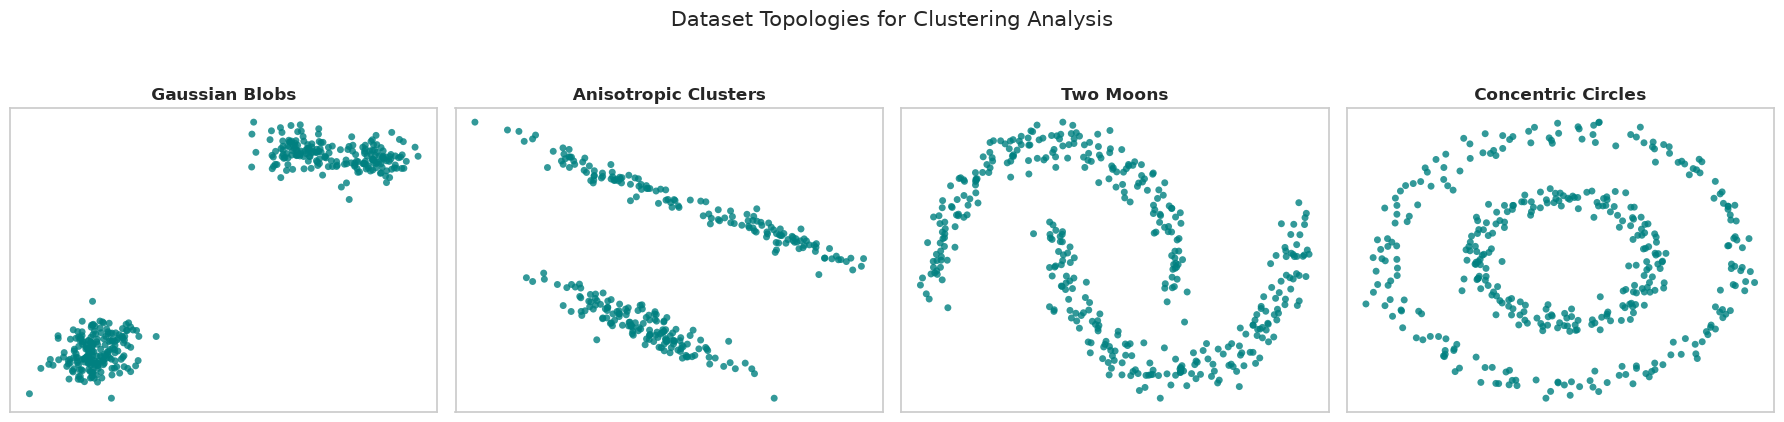

In [2]:
# Generate diverse synthetic topologies to evaluate clustering assumptions
n_samples = 400
seed = 2024

# 1. Isotropic Gaussian Blobs
X_blobs, y_blobs = make_blobs(n_samples=n_samples, centers=4, cluster_std=0.7, random_state=seed)

# 2. Anisotropic Elongated Clusters
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X_blobs[:300], transformation)

# 3. Interlocking Crescent Moons
X_moons, y_moons = make_moons(n_samples=n_samples, noise=0.08, random_state=seed)

# 4. Concentric Circles
X_circles, y_circles = make_circles(n_samples=n_samples, factor=0.5, noise=0.06, random_state=seed)

# Standardize datasets
datasets = {
    "Gaussian Blobs": StandardScaler().fit_transform(X_blobs),
    "Anisotropic Clusters": StandardScaler().fit_transform(X_aniso),
    "Two Moons": StandardScaler().fit_transform(X_moons),
    "Concentric Circles": StandardScaler().fit_transform(X_circles)
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, X_data) in zip(axes, datasets.items()):
    ax.scatter(X_data[:, 0], X_data[:, 1], s=25, alpha=0.8, edgecolors='none', c='teal')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Dataset Topologies for Clustering Analysis", fontsize=15, y=1.05)
plt.tight_layout()
plt.show()

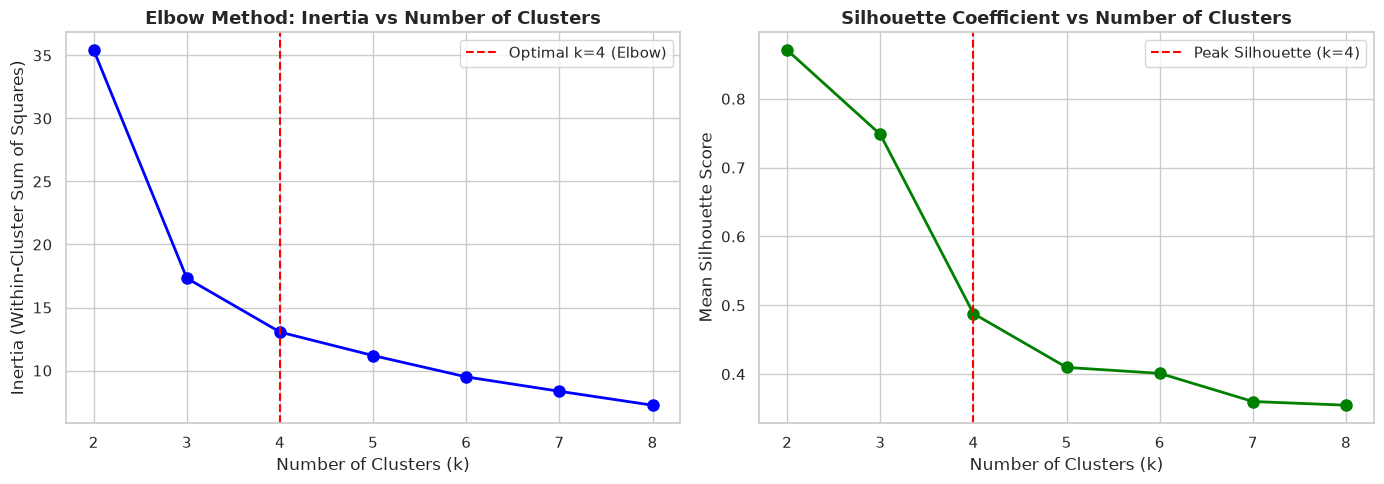

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

X_demo = datasets["Gaussian Blobs"]
k_range = range(2, 9)
inertias = []
silhouettes = []
calinskis = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=seed)
    labels = km.fit_predict(X_demo)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_demo, labels))
    calinskis.append(calinski_harabasz_score(X_demo, labels))

# Plot Elbow Method (Inertia) & Silhouette Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
ax1.set_title("Elbow Method: Inertia vs Number of Clusters", fontsize=13, fontweight='bold')
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Inertia (Within-Cluster Sum of Squares)")
ax1.axvline(x=4, color='r', linestyle='--', label='Optimal k=4 (Elbow)')
ax1.legend()

ax2.plot(k_range, silhouettes, 'go-', linewidth=2, markersize=8)
ax2.set_title("Silhouette Coefficient vs Number of Clusters", fontsize=13, fontweight='bold')
ax2.set_xlabel("Number of Clusters (k)")
ax2.set_ylabel("Mean Silhouette Score")
ax2.axvline(x=4, color='r', linestyle='--', label='Peak Silhouette (k=4)')
ax2.legend()

plt.tight_layout()
plt.show()

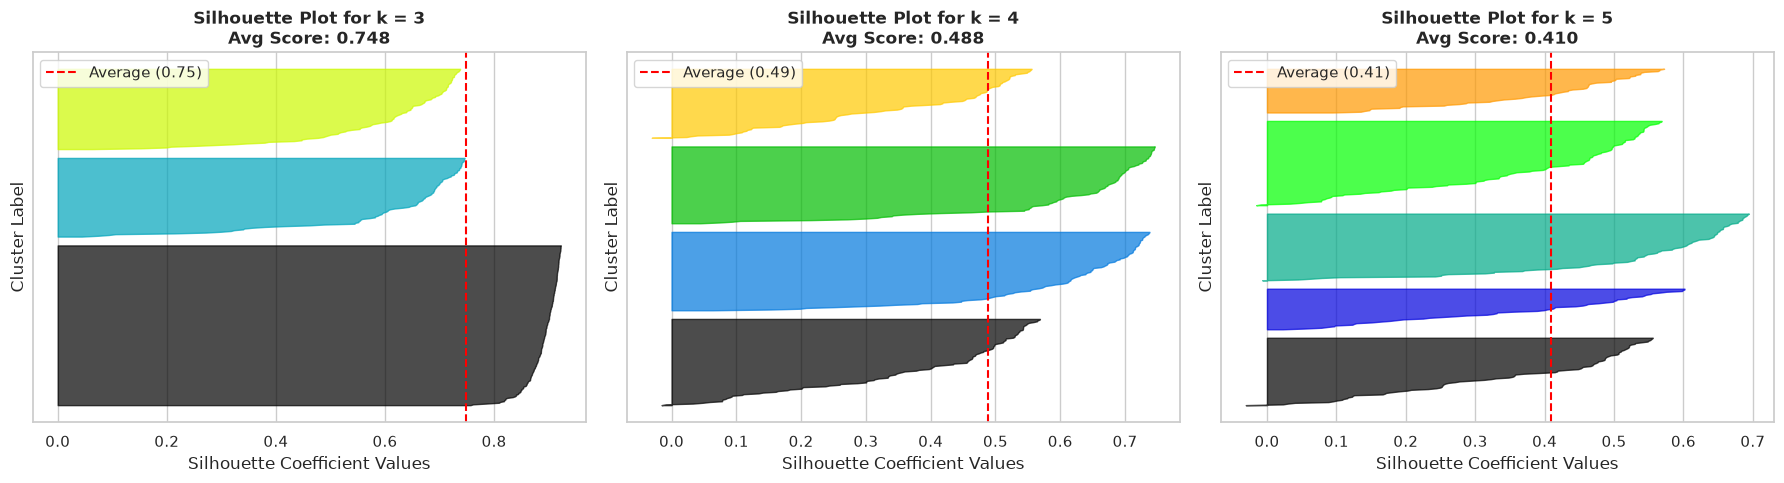

In [4]:
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

# Detailed Silhouette Analysis for k=3, 4, 5
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, k in enumerate([3, 4, 5]):
    ax = axes[i]
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=seed)
    cluster_labels = km.fit_predict(X_demo)
    silhouette_avg = silhouette_score(X_demo, cluster_labels)
    sample_silhouette_values = silhouette_samples(X_demo, cluster_labels)
    
    y_lower = 10
    for j in range(k):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == j]
        ith_cluster_silhouette_values.sort()
        size_cluster_j = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_j
        
        color = cm.nipy_spectral(float(j) / k)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                         facecolor=color, edgecolor=color, alpha=0.7)
        y_lower = y_upper + 10
        
    ax.set_title(f"Silhouette Plot for k = {k}\nAvg Score: {silhouette_avg:.3f}", fontweight='bold')
    ax.set_xlabel("Silhouette Coefficient Values")
    ax.set_ylabel("Cluster Label")
    ax.axvline(x=silhouette_avg, color="red", linestyle="--", label=f"Average ({silhouette_avg:.2f})")
    ax.set_yticks([])
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

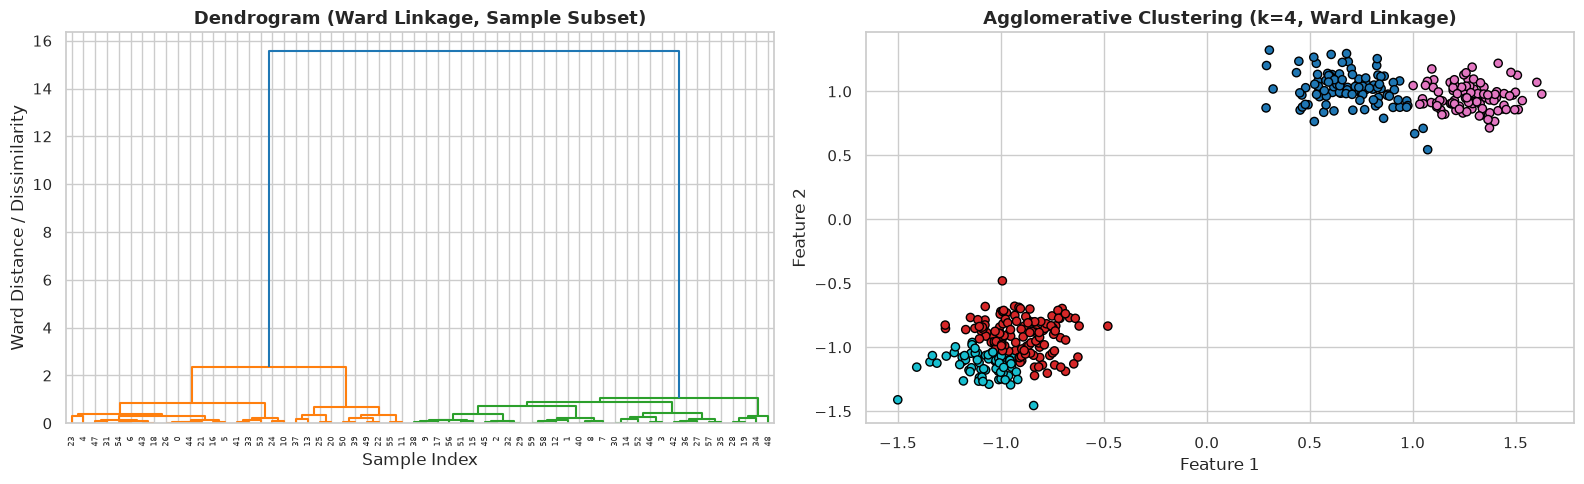

In [5]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Hierarchical Agglomerative Clustering: Linkage Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Compute linkage matrix using Ward's method
linked = linkage(X_demo[:60], method='ward')
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True, ax=axes[0])
axes[0].set_title("Dendrogram (Ward Linkage, Sample Subset)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Sample Index")
axes[0].set_ylabel("Ward Distance / Dissimilarity")

# Fit Agglomerative Clustering with Ward Linkage
agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg.fit_predict(X_demo)

scatter = axes[1].scatter(X_demo[:, 0], X_demo[:, 1], c=agg_labels, cmap='tab10', s=35, edgecolors='k')
axes[1].set_title("Agglomerative Clustering (k=4, Ward Linkage)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

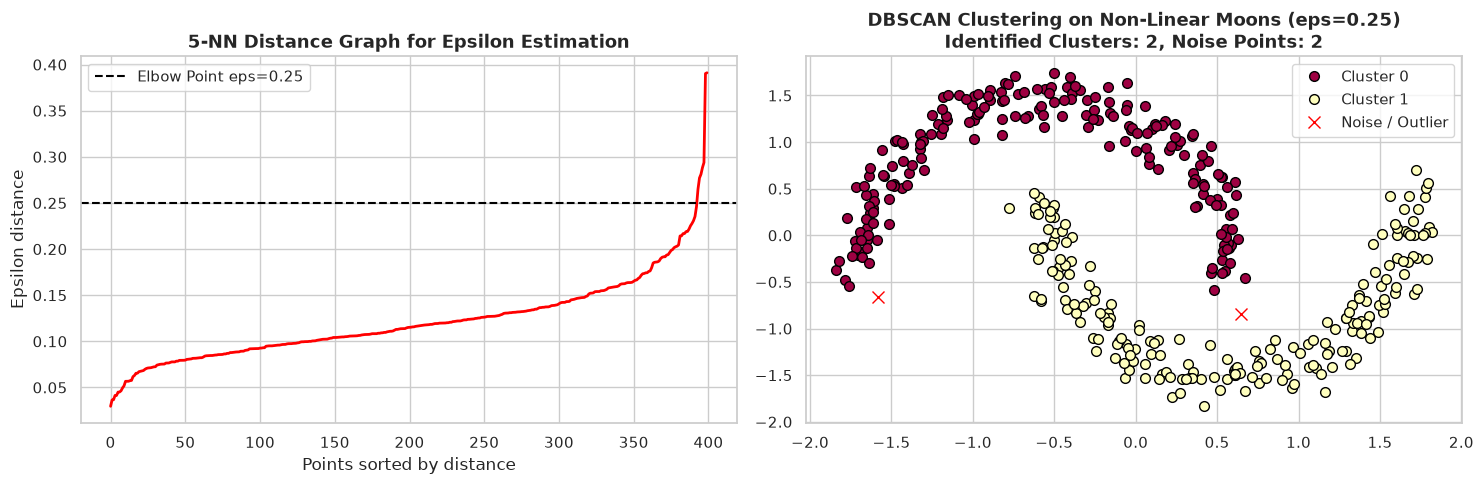

In [6]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# Density-Based Clustering on Two Moons with DBSCAN
X_m = datasets["Two Moons"]

# Step 1: K-Distance Graph to determine optimal epsilon
k_neighbors = 5
nbrs = NearestNeighbors(n_neighbors=k_neighbors).fit(X_m)
distances, _ = nbrs.kneighbors(X_m)
k_distances = np.sort(distances[:, k_neighbors - 1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(k_distances, 'r-', lw=2)
ax1.set_title(f"{k_neighbors}-NN Distance Graph for Epsilon Estimation", fontsize=13, fontweight='bold')
ax1.set_xlabel("Points sorted by distance")
ax1.set_ylabel("Epsilon distance")
ax1.axhline(y=0.25, color='black', linestyle='--', label='Elbow Point eps=0.25')
ax1.legend()

# Step 2: Fit DBSCAN
dbscan = DBSCAN(eps=0.25, min_samples=5)
db_labels = dbscan.fit_predict(X_m)
n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = list(db_labels).count(-1)

# Color points: cluster labels positive, noise point (-1) as red 'x'
unique_labels = set(db_labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k_label, col in zip(unique_labels, colors):
    if k_label == -1:
        col = [1, 0, 0, 1]  # red for noise
        ax2.plot(X_m[db_labels == k_label, 0], X_m[db_labels == k_label, 1], 'x',
                 markerfacecolor=tuple(col), markeredgecolor='red', markersize=8, label='Noise / Outlier')
    else:
        ax2.plot(X_m[db_labels == k_label, 0], X_m[db_labels == k_label, 1], 'o',
                 markerfacecolor=tuple(col), markeredgecolor='k', markersize=7, label=f'Cluster {k_label}')

ax2.set_title(f"DBSCAN Clustering on Non-Linear Moons (eps=0.25)\nIdentified Clusters: {n_clusters_db}, Noise Points: {n_noise}",
              fontsize=13, fontweight='bold')
ax2.legend()
plt.tight_layout()
plt.show()

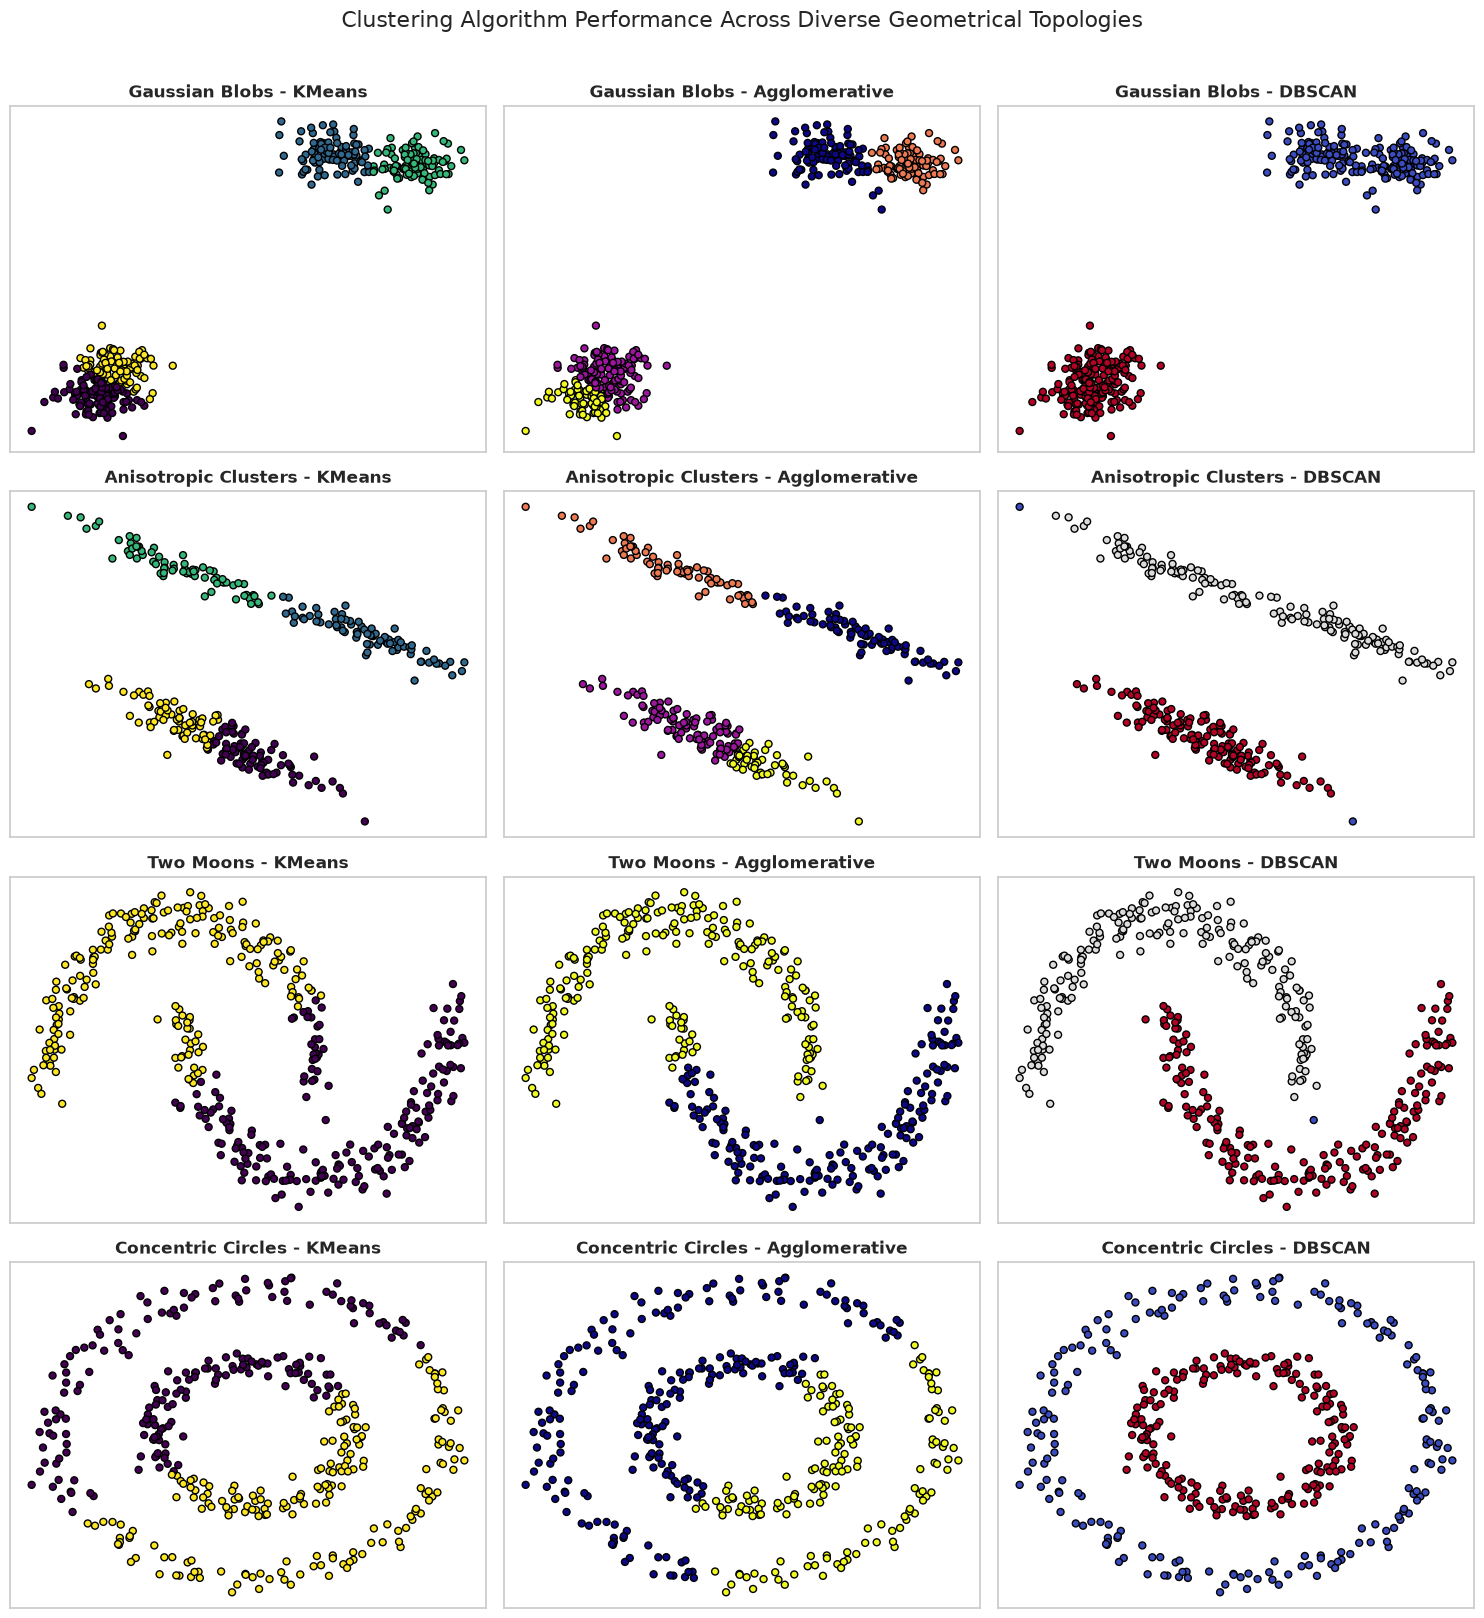

In [7]:
# Comprehensive Topology Comparison: KMeans vs Agglomerative vs DBSCAN
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
topo_names = list(datasets.keys())

for row_idx, topo in enumerate(topo_names):
    X_topo = datasets[topo]
    
    # KMeans
    km = KMeans(n_clusters=2 if 'Moon' in topo or 'Circle' in topo else 4, random_state=seed, n_init=10)
    labels_km = km.fit_predict(X_topo)
    axes[row_idx, 0].scatter(X_topo[:, 0], X_topo[:, 1], c=labels_km, cmap='viridis', s=25, edgecolors='k')
    axes[row_idx, 0].set_title(f"{topo} - KMeans", fontweight='bold')
    axes[row_idx, 0].set_xticks([]); axes[row_idx, 0].set_yticks([])
    
    # Agglomerative
    agg = AgglomerativeClustering(n_clusters=2 if 'Moon' in topo or 'Circle' in topo else 4)
    labels_agg = agg.fit_predict(X_topo)
    axes[row_idx, 1].scatter(X_topo[:, 0], X_topo[:, 1], c=labels_agg, cmap='plasma', s=25, edgecolors='k')
    axes[row_idx, 1].set_title(f"{topo} - Agglomerative", fontweight='bold')
    axes[row_idx, 1].set_xticks([]); axes[row_idx, 1].set_yticks([])
    
    # DBSCAN
    eps_val = 0.28 if 'Circle' in topo or 'Moon' in topo else 0.35
    db = DBSCAN(eps=eps_val, min_samples=5)
    labels_db = db.fit_predict(X_topo)
    axes[row_idx, 2].scatter(X_topo[:, 0], X_topo[:, 1], c=labels_db, cmap='coolwarm', s=25, edgecolors='k')
    axes[row_idx, 2].set_title(f"{topo} - DBSCAN", fontweight='bold')
    axes[row_idx, 2].set_xticks([]); axes[row_idx, 2].set_yticks([])

plt.suptitle("Clustering Algorithm Performance Across Diverse Geometrical Topologies", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

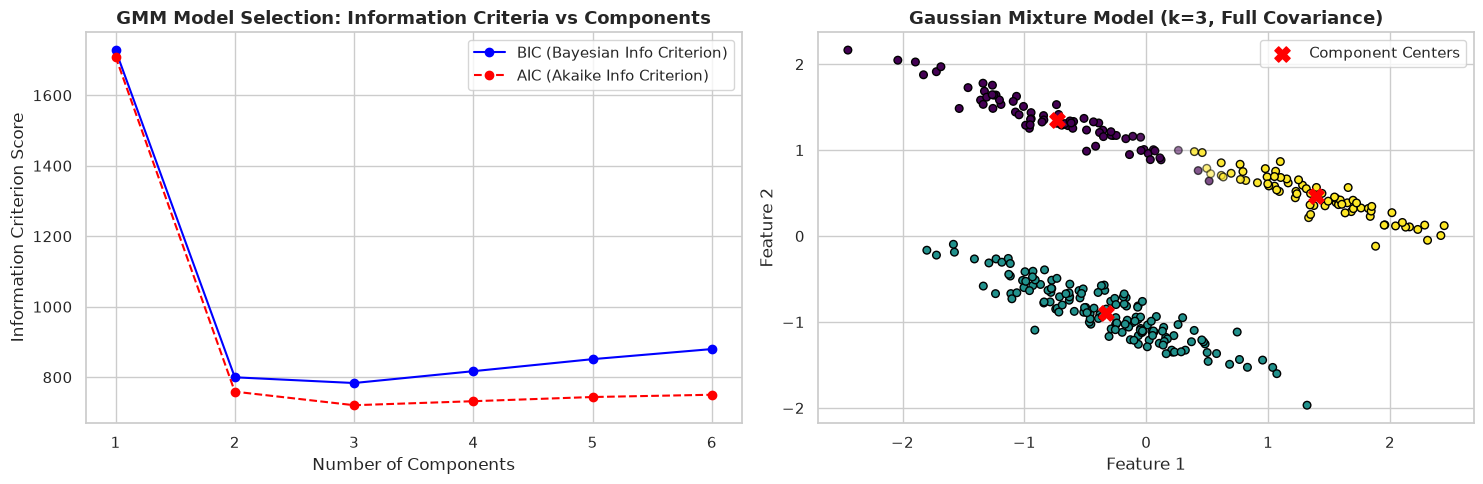

In [8]:
from sklearn.mixture import GaussianMixture
from matplotlib.patches import Ellipse

# Gaussian Mixture Models: Soft Probabilistic Clustering
X_aniso_norm = datasets["Anisotropic Clusters"]

# Model selection via BIC and AIC
n_comp_range = range(1, 7)
bics = []
aics = []
for n in n_comp_range:
    gmm = GaussianMixture(n_components=n, covariance_type='full', random_state=seed)
    gmm.fit(X_aniso_norm)
    bics.append(gmm.bic(X_aniso_norm))
    aics.append(gmm.aic(X_aniso_norm))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(n_comp_range, bics, 'bo-', label='BIC (Bayesian Info Criterion)')
ax1.plot(n_comp_range, aics, 'ro--', label='AIC (Akaike Info Criterion)')
ax1.set_title("GMM Model Selection: Information Criteria vs Components", fontsize=13, fontweight='bold')
ax1.set_xlabel("Number of Components")
ax1.set_ylabel("Information Criterion Score")
ax1.legend()

# Fit optimal GMM
optimal_gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=seed)
optimal_gmm.fit(X_aniso_norm)
gmm_labels = optimal_gmm.predict(X_aniso_norm)
probs = optimal_gmm.predict_proba(X_aniso_norm)

# Visualize clusters with posterior certainty
scatter = ax2.scatter(X_aniso_norm[:, 0], X_aniso_norm[:, 1], c=gmm_labels, cmap='viridis',
                      s=30, alpha=probs.max(axis=1), edgecolors='k')
ax2.scatter(optimal_gmm.means_[:, 0], optimal_gmm.means_[:, 1], c='red', s=120, marker='X', label='Component Centers')
ax2.set_title("Gaussian Mixture Model (k=3, Full Covariance)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
ax2.legend()

plt.tight_layout()
plt.show()

Exercise 1: K-Means Clustering on Iris Dataset:
 - Adjusted Rand Index (ARI): 0.6201
 - Adjusted Mutual Information (AMI): 0.6552
 - Silhouette Score: 0.4599

Exercise 3: High-Dimensional Clustering on Wine Dataset (PCA + GMM):
 - PCA Explained Variance Ratio: 0.5541
 - Wine Clustering Adjusted Rand Index: 0.9135


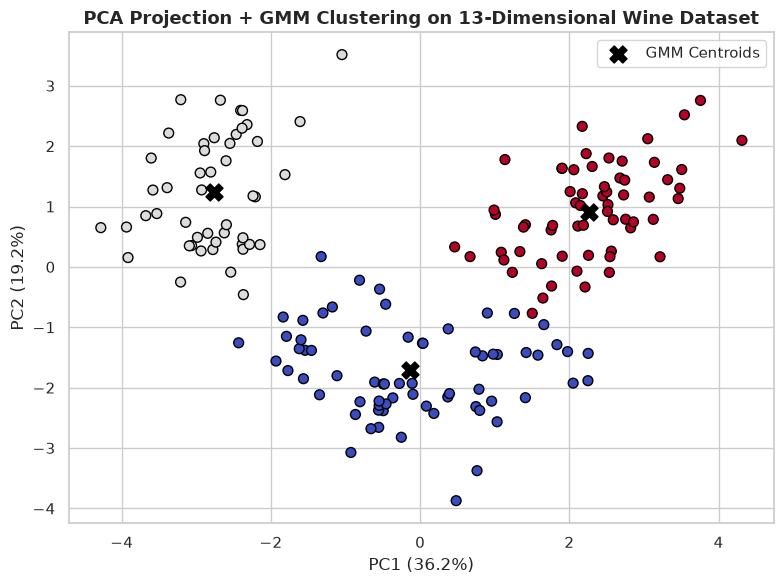

In [9]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.decomposition import PCA

# Exercise 1: K-Means on Iris with Ground-Truth Evaluation
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
y_iris = iris.target

km_iris = KMeans(n_clusters=3, random_state=seed, n_init=10)
labels_iris = km_iris.fit_predict(X_iris)

ari_iris = adjusted_rand_score(y_iris, labels_iris)
ami_iris = adjusted_mutual_info_score(y_iris, labels_iris)
sil_iris = silhouette_score(X_iris, labels_iris)

print("Exercise 1: K-Means Clustering on Iris Dataset:")
print(f" - Adjusted Rand Index (ARI): {ari_iris:.4f}")
print(f" - Adjusted Mutual Information (AMI): {ami_iris:.4f}")
print(f" - Silhouette Score: {sil_iris:.4f}")

# Exercise 2 & 3: High-Dimensional Clustering with PCA + GMM on Wine Dataset
wine = load_wine()
X_wine_scaled = StandardScaler().fit_transform(wine.data)
y_wine = wine.target

pca_wine = PCA(n_components=2)
X_wine_pca = pca_wine.fit_transform(X_wine_scaled)

gmm_wine = GaussianMixture(n_components=3, covariance_type='full', random_state=seed)
labels_wine = gmm_wine.fit_predict(X_wine_pca)

ari_wine = adjusted_rand_score(y_wine, labels_wine)
print("\nExercise 3: High-Dimensional Clustering on Wine Dataset (PCA + GMM):")
print(f" - PCA Explained Variance Ratio: {pca_wine.explained_variance_ratio_.sum():.4f}")
print(f" - Wine Clustering Adjusted Rand Index: {ari_wine:.4f}")

# Visualization of Wine Clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=labels_wine, cmap='coolwarm', s=50, edgecolors='k')
plt.scatter(gmm_wine.means_[:, 0], gmm_wine.means_[:, 1], c='black', marker='X', s=150, label='GMM Centroids')
plt.title("PCA Projection + GMM Clustering on 13-Dimensional Wine Dataset", fontsize=13, fontweight='bold')
plt.xlabel(f"PC1 ({pca_wine.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca_wine.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend()
plt.tight_layout()
plt.show()